In [2]:
# AI-Powered Loan Default Prediction System

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import joblib

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Project environment is ready!")

All libraries imported successfully!
Pandas version: 3.1.1
Scikit-learn version: 1.9.1
Project environment is ready!


In [3]:
# Load the Home Credit dataset

import pandas as pd
import numpy as np

from pathlib import Path

DATA_DIR = Path("data")
TRAIN_PATH = DATA_DIR / "application_train.csv"

# Load dataset
df = pd.read_csv(TRAIN_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Display first 5 rows
display(df.head())

Dataset loaded successfully!
Dataset Shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Target Distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target Percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


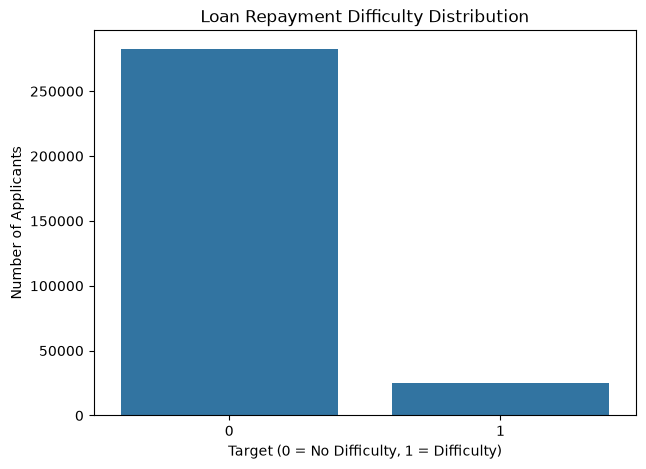

In [4]:
# Check target distribution

target_counts = df["TARGET"].value_counts()

print("Target Distribution:")
print(target_counts)

print("\nTarget Percentage:")
print((df["TARGET"].value_counts(normalize=True) * 100).round(2))

# Visualize target distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="TARGET")

plt.title("Loan Repayment Difficulty Distribution")
plt.xlabel("Target (0 = No Difficulty, 1 = Difficulty)")
plt.ylabel("Number of Applicants")

plt.show()

In [5]:
# Check missing values

missing_values = df.isnull().sum()

missing_percentage = (df.isnull().mean() * 100)

missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

# Show columns with missing values
missing_data = missing_data[
    missing_data["Missing Values"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Total columns:", df.shape[1])
print("Columns containing missing values:", len(missing_data))

display(missing_data.head(20))

Total columns: 122
Columns containing missing values: 67


,Missing Values,Missing Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


In [6]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

# Check missing target values

print("Missing target values:", df["TARGET"].isnull().sum())

# Check dataset information

print("\nDataset Information:")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nData Types:")
print(df.dtypes.value_counts())


Total duplicate rows: 0
Missing target values: 0

Dataset Information:
Total rows: 307511
Total columns: 122

Data Types:
float64    65
int64      41
str        16
Name: count, dtype: int64


In [7]:
# Select important financial features

selected_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

# Statistical summary

display(df[selected_features].describe().round(2))

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,DAYS_BIRTH,DAYS_EMPLOYED
count,3.075110e+05,307511.00,307499.00,307511.00,307511.00
mean,1.687979e+05,599026.00,27108.57,-16037.00,63815.05
std,2.371231e+05,402490.78,14493.74,4363.99,141275.77
min,2.565000e+04,45000.00,1615.50,-25229.00,-17912.00
25%,1.125000e+05,270000.00,16524.00,-19682.00,-2760.00
50%,1.471500e+05,513531.00,24903.00,-15750.00,-1213.00
75%,2.025000e+05,808650.00,34596.00,-12413.00,-289.00
max,1.170000e+08,4050000.00,258025.50,-7489.00,365243.00


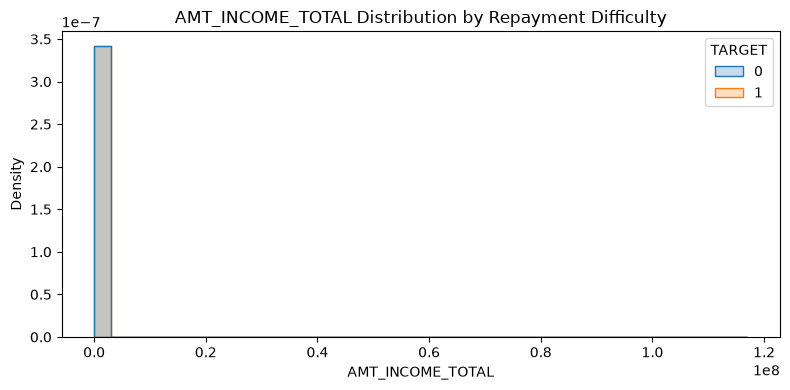

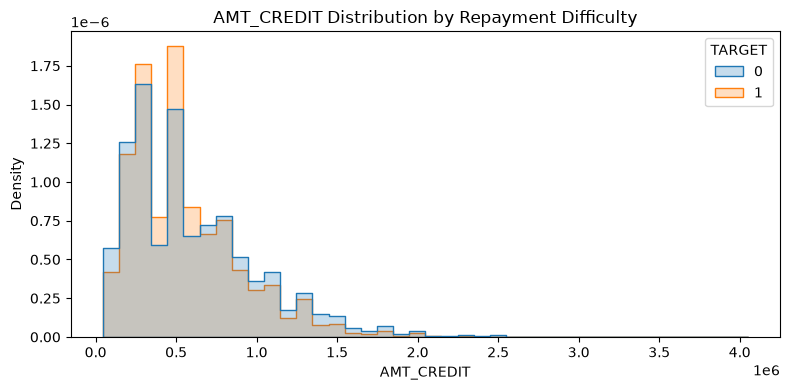

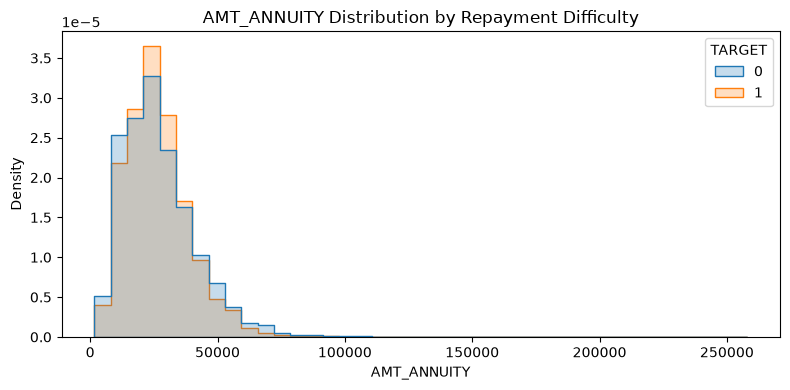

In [8]:
# Visualize financial features

for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        hue="TARGET",
        bins=40,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"{col} Distribution by Repayment Difficulty")
    plt.tight_layout()
    plt.show()

Employment anomaly count: 55374


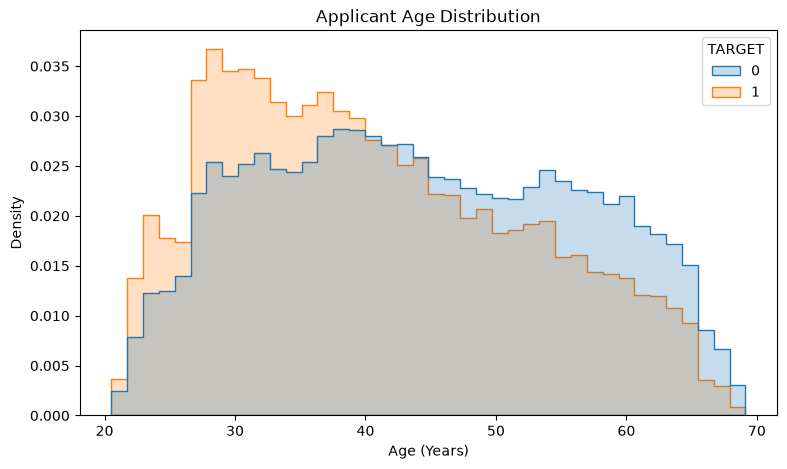

In [9]:
# Convert applicant age into years

df["AGE_YEARS"] = abs(df["DAYS_BIRTH"]) / 365

# Identify employment anomaly

print("Employment anomaly count:",
      (df["DAYS_EMPLOYED"] == 365243).sum())

# Visualize age distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="AGE_YEARS",
    hue="TARGET",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Applicant Age Distribution")
plt.xlabel("Age (Years)")
plt.show()

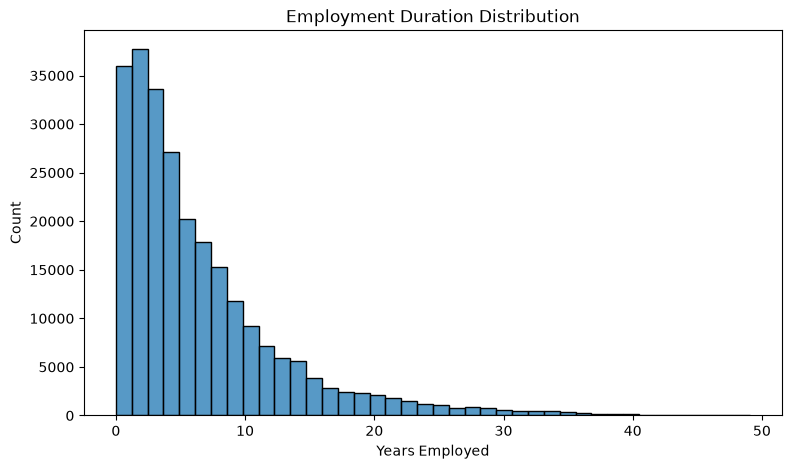

In [10]:
# Analyze employment duration

employment = df[df["DAYS_EMPLOYED"] != 365243].copy()

employment["EMPLOYMENT_YEARS"] = (
    abs(employment["DAYS_EMPLOYED"]) / 365
)

plt.figure(figsize=(9, 5))

sns.histplot(
    data=employment,
    x="EMPLOYMENT_YEARS",
    bins=40
)

plt.title("Employment Duration Distribution")
plt.xlabel("Years Employed")
plt.show()

In [11]:
# FEATURE ENGINEERING

# Avoid DataFrame fragmentation
df = df.copy()

# 1. Convert age into years
df["AGE_YEARS"] = abs(df["DAYS_BIRTH"]) / 365

# 2. Handle employment placeholder
df["EMPLOYMENT_ANOMALY"] = (
    df["DAYS_EMPLOYED"] == 365243
).astype(int)

df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(
    365243, np.nan
)

# 3. Convert employment duration into years
df["EMPLOYMENT_YEARS"] = (
    abs(df["DAYS_EMPLOYED"]) / 365
)

# 4. Credit-to-income ratio
df["CREDIT_INCOME_RATIO"] = (
    df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
)

# 5. Annuity-to-income ratio
df["ANNUITY_INCOME_RATIO"] = (
    df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
)

# Display newly created features

new_features = [
    "AGE_YEARS",
    "EMPLOYMENT_YEARS",
    "EMPLOYMENT_ANOMALY",
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO"
]

display(df[new_features].describe().round(2))

print("Feature engineering completed!")
print("Updated dataset shape:", df.shape)

,AGE_YEARS,EMPLOYMENT_YEARS,EMPLOYMENT_ANOMALY,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO
count,307511.00,252137.00,307511.00,307511.00,307499.00
mean,43.94,6.53,0.18,3.96,0.18
std,11.96,6.41,0.38,2.69,0.09
min,20.52,0.00,0.00,0.00,0.00
25%,34.01,2.10,0.00,2.02,0.11
50%,43.15,4.52,0.00,3.27,0.16
75%,53.92,8.70,0.00,5.16,0.23
max,69.12,49.07,1.00,84.74,1.88


Feature engineering completed!
Updated dataset shape: (307511, 127)


In [12]:
# STEP 16: TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["TARGET", "SK_ID_CURR"])
y = df["TARGET"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display results
print("Training and Testing Split Completed!")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).round(4) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(4) * 100)

Training and Testing Split Completed!

Training Features: (246008, 125)
Testing Features: (61503, 125)

Training Target Distribution:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

Testing Target Distribution:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


In [13]:
# STEP 17: DATA PREPROCESSING

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 109
Categorical features: 16


In [14]:
# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [15]:
# Fit only on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Preprocessing completed!
Training data shape: (246008, 249)
Testing data shape: (61503, 249)


In [16]:
# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()


# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])


# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine preprocessing steps

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [17]:
# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("Training data type:", type(X_train_processed))

Preprocessing completed successfully!
Training data shape: (246008, 249)
Testing data shape: (61503, 249)
Training data type: <class 'numpy.ndarray'>


In [18]:
# STEP 18: LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Model training libraries imported!")

Model training libraries imported!


In [19]:
# Scale features

scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)


# Initialize Logistic Regression

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=3000,
    solver="saga",
    tol=0.001,
    random_state=42,
    n_jobs=-1
)


# Train model

print("Training Logistic Regression...")

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

print("Iterations used:", lr_model.n_iter_)

Training Logistic Regression...


c:\Users\dhairya thakur\OneDrive\Desktop\loan-default-prediction\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression training completed!
Iterations used: [509]


In [20]:
# Generate predictions

y_pred_lr = lr_model.predict(X_test_scaled)

y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Evaluation metrics

print("LOGISTIC REGRESSION RESULTS")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("Precision:", precision_score(y_test, y_pred_lr))

print("Recall:", recall_score(y_test, y_pred_lr))

print("F1 Score:", f1_score(y_test, y_pred_lr))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS
----------------------------------------
Accuracy: 0.6897874900411362
Precision: 0.16130735265885968
Recall: 0.6769385699899295
F1 Score: 0.26053253749854655
ROC-AUC: 0.7484955408080127

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.68      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.68      0.53     61503
weighted avg       0.90      0.69      0.76     61503


Confusion Matrix:
[[39063 17475]
 [ 1604  3361]]
